# Double descent — book graphics 5: many 10th-order fits

Still versions of the "100 perfect 10th-order fits" section of `p46_56.py` (same layout as graphics 4).

- **Fits panel** — the 100 gradient-descent 10th-order fits from `all_fits_degree_10_oct_13_1.npy` (all interpolate the 5 training points) drawn thin in `LT_PURPLE`, with the two curves highlighted in the video on top: GD fit index 66 ("nuts") and the minimum-norm / pseudoinverse degree-10 fit (the video's yellow `fit_line_10`). There is no saved coefficient file for degree 10, so GD train/test MSEs are estimated by interpolating the saved 128-point curves. Exported clipped to `YLIM` and unclipped (same inches-per-unit), and in three variants: all + highlighted, all only, highlighted only.
- **MSE panel** — train / test MSE vs degree, now including degree 10 (the minimum-norm / pseudoinverse fit, which is what the video's numbers come from).

Same data, seed and styling as graphics 1.


## 1. Config

In [1]:
from pathlib import Path
import numpy as np
import scipy.special
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# ── Book palette ───────────────────────────────────────────────────────────
CHILL_BROWN = '#948979'
LT_BLUE     = '#5badb6'
ORANGE      = '#eb8423'
GREEN       = '#419c52'
BLUE        = '#236c94'
RED         = '#d73b2f'
PINK        = '#ed5e78'
LT_PURPLE   = '#b2c2e4'
PURPLE      = '#7e5b76'
YELLOW      = '#fcc947'

AXIS_COLOR   = CHILL_BROWN
CURVE_COLOR  = CHILL_BROWN
TRAIN_COLOR  = LT_BLUE
TEST_COLOR   = ORANGE

# ── Data (matches p46_56.py) ───────────────────────────────────────────────
RANDOM_SEED = 428
N_POINTS    = 10
NOISE_LEVEL = 0.2
TRAIN_FRAC  = 0.5
X_MIN, X_MAX = -2.0, 2.0
def f(x): return 0.5 * x**2

FITS_DIR    = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/double_descent/graphics')
FITS_FILE   = FITS_DIR / 'all_fits_degree_10_oct_13_1.npy'   # (100, 128) curves on np.linspace(-2, 2, 128)
COEFS_FILE  = None                                           # no coefficient file was saved for degree 10
FIT_DEGREE  = 10

# ── Fits panel ─────────────────────────────────────────────────────────────
ALL_FITS_COLOR     = CHILL_BROWN #'#f4ebd9' #LT_PURPLE
ALL_FITS_ALPHA     = 0.35
ALL_FITS_LINEWIDTH = 0.75
BARE_LINEWIDTH     = 1.0           # linewidth for the bare (curves-only) unclipped export
HIGHLIGHT_IDX      = []              # GD fit highlighted in the video (66 = nuts); the chill one is the min-norm fit below
HIGHLIGHT_COLORS   = {} #{66: RED}
HIGHLIGHT_LINEWIDTH = 3.0
SHOW_MIN_NORM      = True              # the degree-10 pseudoinverse (min-norm Legendre) fit = the video's yellow curve
MIN_NORM_COLOR     = YELLOW
MIN_NORM_LINESTYLE = '-'
SHOW_TEST_RESID    = False             # dashed residual lines, test points -> each highlighted fit
RESID_LINEWIDTH    = 1.0
RESID_DASH         = (4, 3)

# ── MSE panel ──────────────────────────────────────────────────────────────
MSE_DEGREES     = [1, 2, 3, 4, 5, 10]
MSE_SOURCE_10   = 'pinv'               # 'pinv' = min-norm Legendre fit (video numbers); 'gd' = GD fit MSE_GD_IDX (interpolated estimate)
MSE_GD_IDX      = 66
MSE_YLIM        = None                 # None = auto, or e.g. (0, 1.5)
MSE_LOG_Y       = False
MSE_SHOW_TRAIN  = True
MSE_SHOW_TEST   = True

# ── Axes / styling (same as graphics 1) ────────────────────────────────────
AX_WIDTH_IN     = 4.0
AX_HEIGHT_IN    = 3.4                  # for the clipped y-range YLIM
MARGIN_IN       = 0.6
LINEWIDTH       = 2.0                  # underlying curve
AXIS_LINEWIDTH  = 1.0
DOT_SIZE        = 100
FONTSIZE        = 18
XLIM            = (X_MIN, X_MAX)
YLIM            = (-0.5, 2.0)          # clipped y-range
UNCLIP_YLIM     = (-30, 30)            # degree-10 GD fits span -1471 .. 745, so the unclipped panel must be capped; None = contain everything
UNCLIP_PAD      = 0.5
X_TICK_STEP     = 1.0
Y_TICK_STEP     = 1.0
UNCLIP_Y_TICK_STEP = 10.0              # tick spacing for the (much taller) unclipped panel
SPINES          = 'lb'
SHOW_TICKS      = True
CURVE_ALPHA     = 0.5
CURVE_LINESTYLE = '-'
TRANSPARENT     = True

# ── Fonts: LaTeX / Computer Modern look ────────────────────────────────────
USE_TEX = True
plt.rcParams['font.family']  = 'serif'
plt.rcParams['font.serif']   = ['cmr10', 'Computer Modern Roman', 'DejaVu Serif']
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['axes.formatter.use_mathtext'] = True
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['text.usetex']  = USE_TEX
plt.rcParams['svg.fonttype'] = 'none'

# ── Output ─────────────────────────────────────────────────────────────────
OUT_DIR = Path('/Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/tenth_order_fits')
SAVE    = True
OUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Fit helpers

In [2]:
def legendre_features(x, degree, x_min=X_MIN, x_max=X_MAX):
    x_scaled = 2 * (x - x_min) / (x_max - x_min) - 1
    return scipy.special.eval_legendre(np.arange(degree + 1)[:, None], x_scaled).T

def fit_legendre_pinv(x_train, y_train, degree):
    return np.linalg.pinv(legendre_features(x_train, degree)) @ y_train

def eval_legendre_poly(beta, x, degree):
    return legendre_features(x, degree) @ beta

def eval_monomial(coefs, x):
    """coefs in increasing degree: c0 + c1 x + c2 x^2 + ...  (the order the GD code saved them in)."""
    return sum(c * x**i for i, c in enumerate(coefs))

def get_noisy_data(n_points=N_POINTS, noise_level=NOISE_LEVEL, random_seed=RANDOM_SEED):
    np.random.seed(random_seed)
    x = np.random.uniform(X_MIN, X_MAX, n_points)
    y = f(x) + noise_level * np.random.randn(n_points)
    return x, y


## 3. Data, pseudoinverse fits, saved GD fits

In [3]:
x, y = get_noisy_data()
n_train = int(np.floor(N_POINTS * TRAIN_FRAC))
x_train, y_train = x[:n_train], y[:n_train]
x_test,  y_test  = x[n_train:], y[n_train:]

all_x = np.linspace(X_MIN, X_MAX, 128)   # the grid the saved fits were evaluated on
all_y = f(all_x)

# pseudoinverse (min-norm) Legendre fits for the MSE panel
pinv = {}
for d in MSE_DEGREES:
    beta = fit_legendre_pinv(x_train, y_train, d)
    pinv[d] = dict(beta=beta, curve=eval_legendre_poly(beta, all_x, d),
                   train_mse=np.mean((y_train - eval_legendre_poly(beta, x_train, d))**2),
                   test_mse =np.mean((y_test  - eval_legendre_poly(beta, x_test,  d))**2))

# the 100 gradient-descent 5th-order fits
gd_fits  = np.load(FITS_FILE)
assert gd_fits.shape[1] == len(all_x)
# no coefficients saved for degree 10 -> estimate each fit's MSE by interpolating its 128-point curve
gd_train_mse = np.array([np.mean((y_train - np.interp(x_train, all_x, c))**2) for c in gd_fits])
gd_test_mse  = np.array([np.mean((y_test  - np.interp(x_test,  all_x, c))**2) for c in gd_fits])

print(f'loaded {len(gd_fits)} GD fits; y-range {gd_fits.min():.2f} .. {gd_fits.max():.2f}')
for i in HIGHLIGHT_IDX:
    print(f'  fit {i}: train ~{gd_train_mse[i]:.4f}  test ~{gd_test_mse[i]:.1f} (interpolated)  range {gd_fits[i].min():.1f} .. {gd_fits[i].max():.1f}')
print(f'  min-norm degree-{FIT_DEGREE} fit: range {pinv[FIT_DEGREE]["curve"].min():.2f} .. {pinv[FIT_DEGREE]["curve"].max():.2f}')
print()
print(f"{'degree':>6} {'train MSE':>10} {'test MSE':>10}   (pseudoinverse / min-norm)")
for d in MSE_DEGREES:
    print(f"{d:>6} {pinv[d]['train_mse']:>10.6f} {pinv[d]['test_mse']:>10.6f}")


loaded 100 GD fits; y-range -1471.01 .. 745.37
  min-norm degree-10 fit: range -0.34 .. 1.29

degree  train MSE   test MSE   (pseudoinverse / min-norm)
     1   0.221350   0.691636
     2   0.031825   0.079449
     3   0.000803   0.727023
     4   0.000000   1.328535
     5   0.000000   0.694120
    10   0.000000   0.481703


## 4. Renderers

In [4]:
X_IN_PER_UNIT = AX_WIDTH_IN  / (XLIM[1] - XLIM[0])
Y_IN_PER_UNIT = AX_HEIGHT_IN / (YLIM[1] - YLIM[0])

def exact_axes(width_in, height_in, margin=MARGIN_IN):
    fig = plt.figure(figsize=(width_in + 2 * margin, height_in + 2 * margin))
    ax = fig.add_axes([margin / fig.get_figwidth(), margin / fig.get_figheight(),
                       width_in / fig.get_figwidth(), height_in / fig.get_figheight()])
    return fig, ax

def style_ax(ax, color=AXIS_COLOR):
    if SPINES == 'lb':
        ax.spines[['top', 'right']].set_visible(False)
    ax.spines[:].set_color(color)
    ax.spines[:].set_linewidth(AXIS_LINEWIDTH)
    ax.tick_params(colors=color, labelsize=FONTSIZE, width=AXIS_LINEWIDTH, which='both')
    ax.xaxis.label.set_color(color)
    ax.yaxis.label.set_color(color)
    if not SHOW_TICKS:
        ax.set_xticks([]); ax.set_yticks([])

def fits_ylim(clip=True, show_all=True, show_highlight=True):
    if clip:
        return YLIM
    if UNCLIP_YLIM is not None:
        return UNCLIP_YLIM
    curves = []
    if show_all:       curves.append(gd_fits)
    if show_highlight: curves.append(gd_fits[HIGHLIGHT_IDX])
    c = np.concatenate(curves) if curves else np.array([YLIM])
    return (min(YLIM[0], c.min() - UNCLIP_PAD), max(YLIM[1], c.max() + UNCLIP_PAD))

def draw_fits(ax, clip=True, show_all=True, show_highlight=True, bare=False):
    """bare=True: only the 100 curves (+ the highlighted ones if show_highlight), no axes / points / underlying curve."""
    ylim = fits_ylim(clip, show_all, show_highlight)
    if bare:
        for c in gd_fits:
            ax.plot(all_x, c, color=ALL_FITS_COLOR, lw=BARE_LINEWIDTH, alpha=ALL_FITS_ALPHA,
                    zorder=2, solid_capstyle='round')
        if show_highlight:
            for i in HIGHLIGHT_IDX:
                ax.plot(all_x, gd_fits[i], color=HIGHLIGHT_COLORS[i], lw=HIGHLIGHT_LINEWIDTH, zorder=5,
                        solid_capstyle='round')
            if SHOW_MIN_NORM:
                ax.plot(all_x, pinv[FIT_DEGREE]['curve'], color=MIN_NORM_COLOR, lw=HIGHLIGHT_LINEWIDTH,
                        ls=MIN_NORM_LINESTYLE, zorder=5, solid_capstyle='round')
        ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
        ax.axis('off')
        return
    ax.plot(all_x, all_y, color=CURVE_COLOR, lw=LINEWIDTH, ls=CURVE_LINESTYLE, alpha=CURVE_ALPHA,
            zorder=1, solid_capstyle='round')
    if show_all:
        for c in gd_fits:
            ax.plot(all_x, c, color=ALL_FITS_COLOR, lw=ALL_FITS_LINEWIDTH, alpha=ALL_FITS_ALPHA,
                    zorder=2, solid_capstyle='round')
    if SHOW_MIN_NORM and show_highlight:
        ax.plot(all_x, pinv[FIT_DEGREE]['curve'], color=MIN_NORM_COLOR, lw=HIGHLIGHT_LINEWIDTH,
                ls=MIN_NORM_LINESTYLE, zorder=4, solid_capstyle='round')
    if show_highlight:
        for i in HIGHLIGHT_IDX:
            ax.plot(all_x, gd_fits[i], color=HIGHLIGHT_COLORS[i], lw=HIGHLIGHT_LINEWIDTH, zorder=5,
                    solid_capstyle='round')
            if SHOW_TEST_RESID:
                yf = np.interp(x_test, all_x, gd_fits[i])
                for xi, yi, yfi in zip(x_test, y_test, yf):
                    ax.plot([xi, xi], [yi, yfi], color=HIGHLIGHT_COLORS[i], lw=RESID_LINEWIDTH,
                            ls=(0, RESID_DASH), zorder=3)
    ax.scatter(x_train, y_train, s=DOT_SIZE, color=TRAIN_COLOR, zorder=6, linewidths=0)
    ax.scatter(x_test,  y_test,  s=DOT_SIZE, color=TEST_COLOR,  zorder=6, linewidths=0)
    ax.set_xlim(*XLIM); ax.set_ylim(*ylim)
    ax.xaxis.set_major_locator(MultipleLocator(X_TICK_STEP))
    ax.yaxis.set_major_locator(MultipleLocator(Y_TICK_STEP if clip else UNCLIP_Y_TICK_STEP))
    style_ax(ax)

def fits_figure(clip=True, show_all=True, show_highlight=True, bare=False):
    ylim = fits_ylim(clip, show_all, show_highlight)
    fig, ax = exact_axes(AX_WIDTH_IN, (ylim[1] - ylim[0]) * Y_IN_PER_UNIT)
    draw_fits(ax, clip, show_all, show_highlight, bare)
    return fig, ax

def mse_points():
    degs, tr, te = [], [], []
    for d in MSE_DEGREES:
        if d == FIT_DEGREE and MSE_SOURCE_10 == 'gd':
            tr.append(gd_train_mse[MSE_GD_IDX]); te.append(gd_test_mse[MSE_GD_IDX])
        else:
            tr.append(pinv[d]['train_mse']); te.append(pinv[d]['test_mse'])
        degs.append(d)
    return np.array(degs), np.array(tr), np.array(te)

def draw_mse(ax):
    degs, tr, te = mse_points()
    if MSE_SHOW_TRAIN:
        ax.scatter(degs, tr, s=DOT_SIZE, color=TRAIN_COLOR, zorder=3, linewidths=0)
    if MSE_SHOW_TEST:
        ax.scatter(degs, te, s=DOT_SIZE, color=TEST_COLOR, zorder=3, linewidths=0)
    ax.set_xlim(degs.min() - 0.5, degs.max() + 0.5)
    ax.set_xticks(degs)
    if MSE_LOG_Y:
        ax.set_yscale('log')
    elif MSE_YLIM is None:
        top = max(tr.max() if MSE_SHOW_TRAIN else 0, te.max() if MSE_SHOW_TEST else 0)
        ax.set_ylim(0, 1.1 * top)
    else:
        ax.set_ylim(*MSE_YLIM)
    style_ax(ax)

def mse_figure():
    fig, ax = exact_axes(AX_WIDTH_IN, AX_HEIGHT_IN)
    draw_mse(ax)
    return fig, ax


## 5. Preview

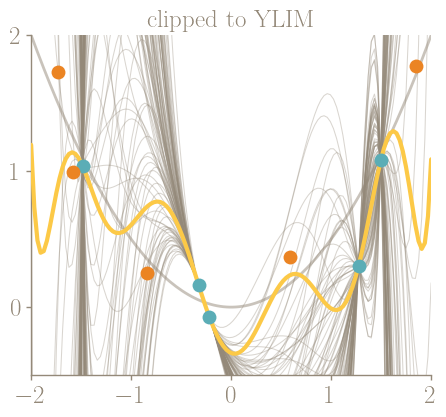

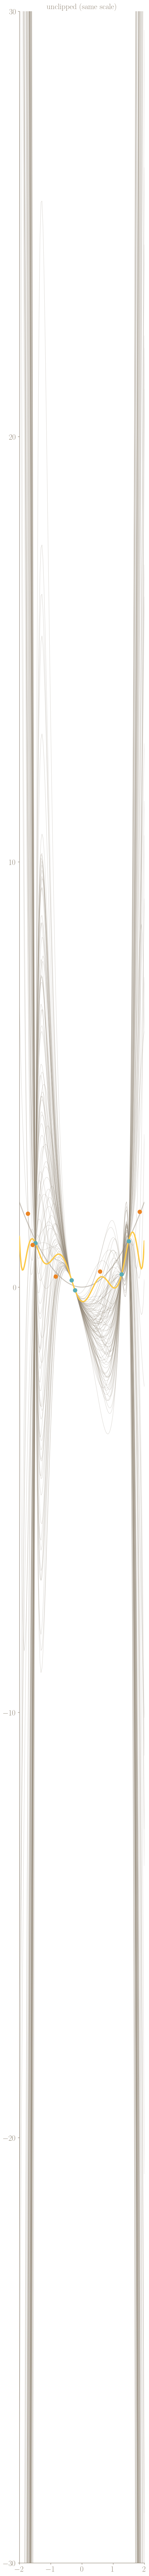

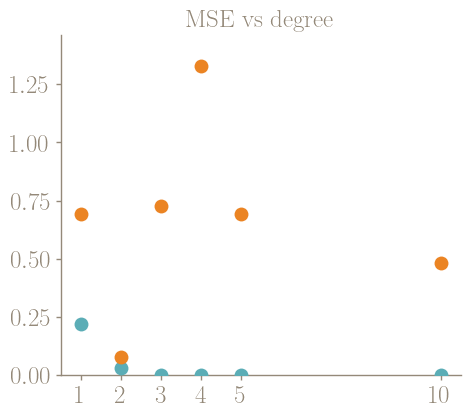

In [5]:
for clip in (True, False):
    fig, ax = fits_figure(clip=clip)
    ax.set_title('clipped to YLIM' if clip else 'unclipped (same scale)', color=AXIS_COLOR, fontsize=FONTSIZE)
    plt.show()
fig, ax = mse_figure(); ax.set_title('MSE vs degree', color=AXIS_COLOR, fontsize=FONTSIZE); plt.show()


## 6. Export

In [6]:
def save(fig, stem, tight=True):
    for ext in ('svg', 'png'):
        fig.savefig(OUT_DIR / f'{stem}.{ext}', dpi=300, transparent=TRANSPARENT,
                    bbox_inches='tight' if tight else None)
    plt.close(fig)

if SAVE:
    variants = {'all_highlighted': (True, True), 'all': (True, False), 'highlighted': (False, True)}
    for name, (show_all, show_hl) in variants.items():
        for clip in (True, False):
            if name == 'all' and not clip:
                # bare: 100 curves + the two highlighted ones, no axes/points; canvas = axes box + MARGIN_IN border
                fig, _ = fits_figure(clip, show_all, show_highlight=True, bare=True)
                save(fig, 'fits10_all_unclipped', tight=False)
                continue
            fig, _ = fits_figure(clip, show_all, show_hl)
            save(fig, f'fits10_{name}' + ('' if clip else '_unclipped'))
    fig, _ = mse_figure(); save(fig, 'mse_vs_degree_1to' + str(max(MSE_DEGREES)))
    print('saved to', OUT_DIR)
    for p in sorted(OUT_DIR.glob('*.svg')):
        print('  ', p.name)


saved to /Users/stephen/Library/CloudStorage/Dropbox-Stephencwelch/welch_labs/ai_book_vol_2/5_double_descent/graphics/tenth_order_fits
   fits10_all.svg
   fits10_all_highlighted.svg
   fits10_all_highlighted_unclipped.svg
   fits10_all_unclipped.svg
   fits10_highlighted.svg
   fits10_highlighted_unclipped.svg
   mse_vs_degree_1to10.svg
